dataset 5 code (after first step calculation)

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os

def get_df(fasta_file):
   
    record_dict = SeqIO.to_dict(SeqIO.parse(fasta_file, "fasta"))
    sequence_list_original = [str(record.seq) for record in record_dict.values() if 12 <= len(record.seq) <= 44]
    # sequence_list_original = [str(record.seq) for record in record_dict.values()]
    df = pd.DataFrame(sequence_list_original, columns=["sequence"])
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)
    
    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    # print(value_counts)

    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }

    base_path = "../../../../5th_9samples_output"
    total_names = [
        "SRR8195524", "SRR8195525", "SRR8195526",
        "SRR8195527", "SRR8195528", "SRR8195529",
        "SRR8195530", "SRR8195531", "SRR8195532"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"

    color_list = [  '#1f77b4',  # Blue
                    '#ff7f0e',  # Orange
                    '#2ca02c',  # Green
                    '#d62728',  # Red
                    '#9467bd',  # Purple
                    '#8c564b',  # Brown
                    '#e377c2',  # Pink
                    '#7f7f7f',  # Gray
                    '#bcbd22']  # Yellow-green
    # color_list = ['#1f77b4', '#ff7f0e', '#2ca02c']

    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  
        fasta_file = os.path.join(base_path, name, "extract/final_seq_12.fasta")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)
        
      
        df = get_df(fasta_file)
        print(f"Processed: {fasta_file}")
        print(df)
        
        # Extract sample name from the file name (e.g., 'final_seq_12_831.fasta' -> 'SRR20723831')
        sample_name = name
        

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)


    plt.figure(figsize=(12, 6)) 
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list  
    )


    ax.set_xlabel("Length (nt)", fontsize=14, weight='bold')
    ax.set_ylabel("Number of Reads (x10^6)", fontsize=14, weight='bold')
    ax.set_title("Read Distribution by Length", fontsize=16, weight='bold')


    ax.legend(title="Sample", fontsize=12, title_fontsize=14, loc='upper right')

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    #plt.show()
    plt.savefig(os.path.join(base_path, "5th_samples_after_clean_12_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

ModuleNotFoundError: No module named 'seaborn'

dataset 3 code (after first step calculation)

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os

def get_df(fasta_file):

    record_dict = SeqIO.to_dict(SeqIO.parse(fasta_file, "fasta"))
    sequence_list_original = [str(record.seq) for record in record_dict.values()]
    # sequence_list_original = [str(record.seq) for record in record_dict.values()]
    df = pd.DataFrame(sequence_list_original, columns=["sequence"])
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)

    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    # print(value_counts)

    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }

    base_path = "../../../../3rd_3samples_output"
    total_names = [
        "SRR20723831", "SRR20723832", "SRR20723833"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"

    # color_list = [  '#1f77b4',  # Blue
    #                 '#ff7f0e',  # Orange
    #                 '#2ca02c',  # Green
    #                 '#d62728',  # Red
    #                 '#9467bd',  # Purple
    #                 '#8c564b',  # Brown
    #                 '#e377c2',  # Pink
    #                 '#7f7f7f',  # Gray
    #                 '#bcbd22']  # Yellow-green
    # color_list = ['#1f77b4', '#ff7f0e', '#2ca02c']
    color_list = ["#5CA9DD","#E2E867","#99cc99"]


    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  # Process only FASTA files
        fasta_file = os.path.join(base_path, name, "extract/final_seq_12.fasta")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)
        

        df = get_df(fasta_file)
        print(f"Processed: {fasta_file}")
        print(df)
        
        # Extract sample name from the file name (e.g., 'final_seq_12_831.fasta' -> 'SRR20723831')
        sample_name = name
        

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)


    plt.figure(figsize=(12, 6))  
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list  
    )


    ax.set_xlabel("Length (nt)", fontsize=14, weight='bold')
    ax.set_ylabel("Number of Reads (x10^6)", fontsize=14, weight='bold')
    ax.set_title("Read Distribution by Length", fontsize=16, weight='bold')

    ax.legend(title="Sample", fontsize=12, title_fontsize=14, loc='upper right')

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    #plt.show()
    plt.savefig(os.path.join(base_path, "3rd_samples_after_clean_12_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

dataset 5 code (after all step finished, then calculation)

aaa
before
1151531
after
1151531
before
33096
after
33096
before
1040781
after
1040781
before
1122635
after
1122635
before
546953
after
546953
before
1128618
after
1128618
before
1474716
after
1474716
before
1411724
after
1411724
before
1111881
after
1111881


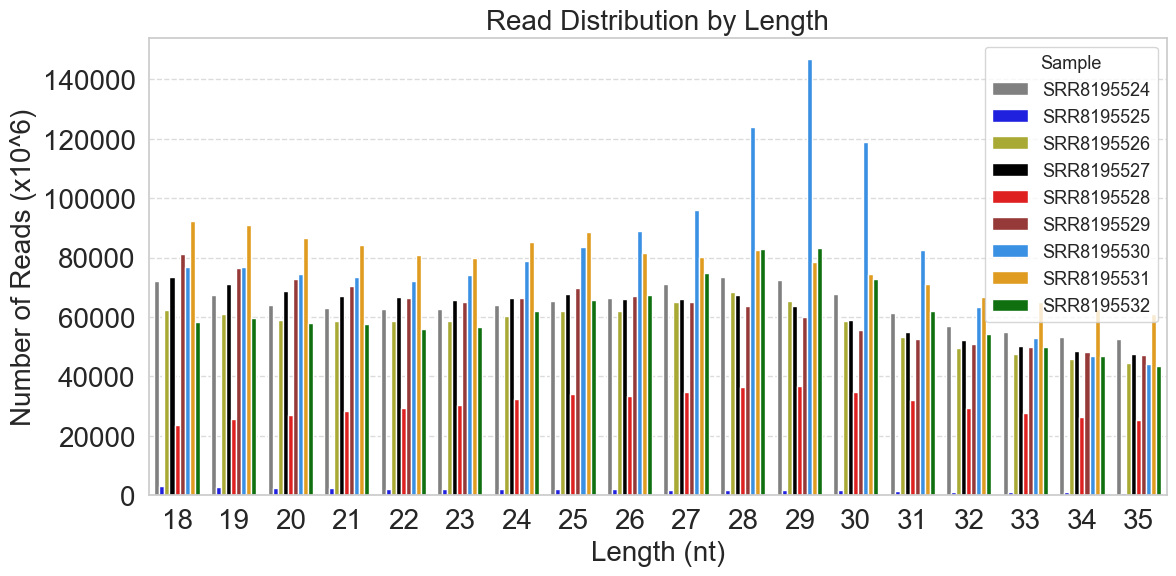

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=20)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=13)
print("aaa")
def get_df(fasta_file):

    # sequence_list_original = [str(record.seq) for record in record_dict.values()]
    df = pd.read_csv(fasta_file, sep=',', usecols=[0])
    print("before")
    print(len(df))
    df_temp = df.drop_duplicates()
    print("after")
    print(len(df_temp))
    # df = pd.DataFrame(sequence_list_original, columns=["sequence"])
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)

    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    # print(value_counts)

    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }

    base_path = "../../../../5th_9samples_output"
    code_path ="../../../../code/python/after_cleaning/analysis"
    total_names = [
        "SRR8195524", "SRR8195525", "SRR8195526",
        "SRR8195527", "SRR8195528", "SRR8195529",
        "SRR8195530", "SRR8195531", "SRR8195532"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"

    # color_list = [  '#1f77b4',  # Blue
    #                 '#ff7f0e',  # Orange
    #                 '#2ca02c',  # Green
    #                 '#d62728',  # Red
    #                 '#9467bd',  # Purple
    #                 '#8c564b',  # Brown
    #                 '#e377c2',  # Pink
    #                 '#7f7f7f',  # Gray
    #                 '#bcbd22']  # Yellow-green
    # color_list = [ "#C9A0DC",  # Adipose Tissue - light purple
    # "#87CEEB",  # Adrenal Gland - sky blue
    # "#FF9999",  # Blood - soft red
    # "#FFD700",  # Colon - light gold
    # "#A2CD5A",  # Kidney - light green
    # "#FF69B4",  # Liver - pink
    # "#DA70D6",  # Nerve - orchid
    # "#66CDAA",  # Ovary - aquamarine
    # "#BC8F8F"  # Pituitary - rosy brown
    # ]  
    color_list =[
        "gray",
        "blue",
        "#bcbd22",
        "black",
        "red",
        "brown",
        "#1E90FF",
        "orange",
        "green"
    ]# Yellow-green
    # color_list = ['#1f77b4', '#ff7f0e', '#2ca02c']

    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  
        fasta_file = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)
        

        df = get_df(fasta_file)
        # print(f"Processed: {fasta_file}")
        # print(df)
        
        # Extract sample name from the file name (e.g., 'final_seq_12_831.fasta' -> 'SRR20723831')
        sample_name = name

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)


    plt.figure(figsize=(12, 6)) 
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list  
    )


    ax.set_xlabel("Length (nt)", weight='bold',fontproperties=arial_font)
    ax.set_ylabel("Number of Reads (x10^6)", weight='bold',fontproperties=arial_font)
    ax.set_title("Read Distribution by Length", weight='bold',fontproperties=arial_font)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontproperties(arial_font)

    ax.legend(title="Sample", loc='upper right',
            prop=arial_font_in, title_fontproperties=arial_font_in)

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    # plt.xticks(fontproperties=arial_font)
    plt.savefig("figure3_A.pdf", format="pdf", bbox_inches="tight")
    # plt.savefig(os.path.join(code_path, "5th_samples_after_all_step_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

dataset 3 code (after all step finished, then calculation)

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=25)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=18)
print("aaa")

def get_df(fasta_file):
    df = pd.read_csv(fasta_file, sep=',', usecols=[0])
    print("before")
    print(len(df))
    df_temp = df.drop_duplicates()
    print("after")
    print(len(df_temp))
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)

    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    # print(value_counts)

    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }

    base_path = "../../../../3rd_3samples_output"
    total_names = [
        "SRR20723831", "SRR20723832", "SRR20723833"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"
    # Define a color list with 9 different colors
    # color_list = [  '#1f77b4',  # Blue
    #                 '#ff7f0e',  # Orange
    #                 '#2ca02c',  # Green
    #                 '#d62728',  # Red
    #                 '#9467bd',  # Purple
    #                 '#8c564b',  # Brown
    #                 '#e377c2',  # Pink
    #                 '#7f7f7f',  # Gray
    #                 '#bcbd22']  # Yellow-green
    # color_list = ['#1f77b4', '#ff7f0e', '#2ca02c']
    color_list = ["firebrick","#E2E867","royalblue"]

    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  # Process only FASTA files
        fasta_file = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)

        df = get_df(fasta_file)
        print(f"Processed: {fasta_file}")
        print(df)
        
        # Extract sample name from the file name (e.g., 'final_seq_12_831.fasta' -> 'SRR20723831')
        sample_name = name

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)

    plt.figure(figsize=(12, 6))  
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list  
    )


    ax.set_xlabel("Length (nt)", weight='bold',fontproperties=arial_font)
    ax.set_ylabel("Number of Reads", weight='bold',fontproperties=arial_font)
    ax.set_title("Read Distribution by Length",  weight='bold',fontproperties=arial_font)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontproperties(arial_font)

    ax.legend(title="Sample", loc='upper right',
            prop=arial_font, title_fontproperties=arial_font)

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    # plt.xticks(fontproperties=arial_font)
    plt.savefig("figure4_A.pdf", format="pdf", bbox_inches="tight")
    plt.show()
    # plt.savefig(os.path.join(code_path, "5th_samples_after_all_step_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
from Bio import SeqIO

# Convert fastq to fasta
SeqIO.convert("data/input.fastq", "fastq", "output.fasta", "fasta")
